# 10 · pdCREs around orthologous gastrulation genes (Fig 6, Fig S11C)

For 146 genes whose expression correlates best between the two species (RBOGs), the pdCREs within 4 Mb of their TSSs: each
pdCRE linked to the nearest TSS of each gene (one link per pdCRE and gene), its distance, class and the correlation of its
accessibility with the gene's expression over the 24 homologous states.

1. **RNA by state**: expression of every gene per state (log2 of the state's fraction of UMIs).
2. **Shared tables**: the 24 homologous states, their colours, the CRECl groups and names.
3. **Links and classes**: the gene density classes (mouse pdCREs 2-100 kb: low <= 6, mid 7-13, high >= 14), distance bins,
   p2p fractions, accessibility-expression correlations and the conserved pairs (p2p, r > 0.4 in both species).
4. **Figs 6A-D**: the pdCRE landscape of each gene (A), pdCRE density (B), and the fractions of pdCREs that are p2p (C)
   and that correlate with expression, r > 0.4 (D), by distance and density class.
5. **Figs 6E, 6F**: example pairs (E) and the Pdgfra locus in mouse ES-cell Hi-C (F; Bonev et al. 2017): shaman score
   map, virtual 4C from the TSS, the linked pdCREs and the genes.
6. **Fig S11C**: contact of high-correlation p2p and non-p2p pdCREs with the TSS of the linked gene in mouse ES-cell Hi-C
   and Micro-C (Hsieh et al. 2020), by distance.

The panels of Figs 6A-F are drawn off-screen at their print size and 600 dpi and put together as in the paper.

## Setup

In [1]:
source("../R/setup.R")
suppressPackageStartupMessages({library(data.table); library(shaman); library(patchwork)})
fread = data.table::fread; fwrite = data.table::fwrite
source("../R/sup_style.R")
suppressMessages(library(ggtext))
out_dir = out_path("10_gene_neighbourhoods")
O = OUT_DIR             # outputs of notebooks 01, 02, 05, 06
TABD = out_dir          # tables of this notebook, read back by its later cells
# a panel (ggplot / patchwork, or a function that draws) rendered off-screen at its print size: the pixels of its
# 600-dpi PNG, as png::readPNG returns them
render_panel <- function(p, w, h, dpi = 600) {
    cap <- ragg::agg_capture(width = w, height = h, units = "in", res = dpi)
    if (is.function(p)) p() else print(p)
    r <- cap(native = FALSE); invisible(dev.off())
    array(t(col2rgb(r)) / 255, c(nrow(r), ncol(r), 3))
}

## 1. RNA by state

Expression of every gene per state: log2 of the state's fraction of RNA UMIs.

In [2]:
states <- readRDS(file.path(O, "02_states", "states.rds")); mm_sup <- states$mm_sup; oc_sup <- states$oc_sup
mm_smc_rna_sum <- as.data.frame(data.table::fread(data_path("mm_smc_rna_sum.csv")))
rownames(mm_smc_rna_sum) <- 1:300
colnames(mm_smc_rna_sum) <- toupper(colnames(mm_smc_rna_sum))
oc_mc_rna_sum <- as.matrix(data.frame(data.table::fread(data_path("oc_mc_rna_umis.csv")), row.names = 1, check.names = FALSE))
rownames(oc_mc_rna_sum) <- gsub(".[0-9]+$", "", gsub("^M", "mc", rownames(oc_mc_rna_sum)))
mm_sum_by_sup <- t(col_group_sums(t(as.matrix(mm_smc_rna_sum[names(mm_sup), ])), mm_sup))
oc_sum_by_sup <- t(col_group_sums(t(oc_mc_rna_sum[names(oc_sup), ]), oc_sup))
mm_rna_by_sup_legc <- log2(1e-5 + t(t(mm_sum_by_sup) / colSums(mm_sum_by_sup)))
oc_rna_by_sup_legc <- log2(1e-5 + t(t(oc_sum_by_sup) / colSums(oc_sum_by_sup)))
tgutil::fwrite(data.frame(gene = rownames(mm_rna_by_sup_legc), mm_rna_by_sup_legc, check.names = FALSE), file.path(TABD, "mm_rna_by_sup_legc.csv"))
tgutil::fwrite(data.frame(gene = rownames(oc_rna_by_sup_legc), oc_rna_by_sup_legc, check.names = FALSE), file.path(TABD, "oc_rna_by_sup_legc.csv"))
rm(mm_smc_rna_sum, oc_mc_rna_sum)

## 2. Shared tables

The 24 homologous states (in the order of `rbomcs.csv`, which sets the drawing order of the points in E), their colours,
the CRECl groups and the CRECl names.

In [3]:
rbomcs <- fread(data_path("rbomcs.csv"))
cap1 <- function(x) paste0(toupper(substr(x, 1, 1)), substring(x, 2))
# a state's type = the atlas type of most of its metacells, a tie broken by cells
mm_state_types <- local({
    cc <- fread(data_path("mm_mc_cells.csv"))
    d <- merge(fread(file.path(O, "02_states", "mc_type_mm_smc_sup.csv"))[!is.na(sup) & sup != ""], cc[, .(metacell, cells)], by = "metacell", all.x = TRUE)
    stopifnot(!anyNA(d$cells))
    t <- d[, .(metacells = .N, cells = sum(cells), colour = toupper(color[1])), by = .(state = sup, cell_type)]
    setorder(t, state, -metacells, -cells)
    t[, rank := seq_len(.N), by = state]
    t[, tie := { m <- metacells == max(metacells); sum(m & cells == max(cells[m])) > 1 }, by = state]
    stopifnot(!any(t$tie))
    t[, name := cap1(cell_type)]
    t
})
mm_name <- with(mm_state_types[rank == 1], setNames(name, state))
mm_name_col <- local({ k <- unique(mm_state_types[rank == 1, .(name, colour)]); stopifnot(!anyDuplicated(k$name)); setNames(k$colour, k$name) })
homolog_states <- local({
    d <- copy(rbomcs)[, mouse_type := mm_name[mouse_mcc]][, color := mm_name_col[mouse_type]]
    stopifnot(!anyNA(d$color))
    d[, .(mouse_mcc, rabbit_mcc, mouse_type, color)]
})
# CRECl groups (Fig 4) and display names
mm_paper <- c(`75` = "1", `74` = "1.1", `45` = "2", `73` = "3", `44` = "4", `60` = "5", `59` = "5.1", `49` = "5.2", `48` = "5.3",
  `89` = "6", `90` = "6.1", `100` = "6.2", `40` = "7", `97` = "8", `98` = "8.1", `99` = "8.2", `4` = "9", `3` = "9.1", `14` = "9.2",
  `18` = "10", `15` = "10.1", `6` = "10.2", `2` = "11", `1` = "11.1", `30` = "12", `32` = "12.1", `28` = "12.2", `77` = "13",
  `78` = "13.1", `76` = "14", `11` = "15",
  `34` = "16", `33` = "16.1", `35` = "16.2", `46` = "16.3", `41` = "16.4", `54` = "17", `55` = "17.1", `53` = "17.2", `37` = "17.3",
  `51` = "17.4", `42` = "18", `36` = "18.1", `50` = "19", `57` = "20", `64` = "20.1", `62` = "20.2", `65` = "20.3", `63` = "20.4",
  `58` = "21", `69` = "21.1", `61` = "22", `86` = "23", `85` = "23.1", `88` = "23.2", `82` = "24", `93` = "25", `96` = "26",
  `95` = "26.1", `94` = "26.2", `79` = "27", `80` = "27.1", `84` = "28", `16` = "29", `8` = "30", `7` = "30.1", `10` = "30.2",
  `9` = "30.3", `12` = "31", `13` = "31.1", `17` = "31.2", `24` = "32", `25` = "32.1", `26` = "32.2", `31` = "32.3", `27` = "32.4",
  `92` = "33", `91` = "33.1")
mm_pan <- c("29", "38", "67", "68", "71", "72")
mm_erythroid <- as.character(19:23)
mm_erythroid_lab <- setNames(paste0("h", seq_along(mm_erythroid)), mm_erythroid)
mm_pan_lab <- c(`67` = "c1", `38` = "c2", `29` = "c3", `72` = "c4", `68` = "c5", `71` = "c6")
grp_code <- c(`29`="c",`38`="c",`67`="c",`68`="c",`71`="c",`72`="c",`69`="vA",`37`="vA",`64`="vA",`61`="vA",`58`="vA",`63`="vA",
  `65`="vA",`57`="vA",`62`="vA",`49`="vA1",`60`="vA1",`48`="vA1",`59`="vA1",`53`="vA1",`84`="vB",`82`="vB",`79`="vB",`80`="vB",
  `93`="vB",`86`="vB",`85`="vB",`88`="vB",`11`="vB1",`77`="vB1",`78`="vB1",`76`="vB1",`55`="vB2",`36`="vB2",`34`="vB2",`33`="vB2",
  `41`="vB2",`54`="vB2",`35`="vB2",`42`="vB2",`46`="vB12",`50`="vB12",`51`="vB12",`98`="vC",`99`="vC",`97`="vC",`89`="vD",`90`="vD",
  `40`="vD",`100`="vD",`94`="vD",`96`="vD",`95`="vD",`2`="vZ",`15`="vZ",`28`="vZ",`6`="vZ",`14`="vZ",`30`="vZ",`1`="vZ",`4`="vZ",
  `18`="vZ",`3`="vZ",`16`="vZ",`10`="vZ",`8`="vZ",`13`="vZ",`12`="vZ",`17`="vZ",`32`="vZb",`25`="vZb",`27`="vZb",`31`="vZb",
  `24`="vZb",`19`="vZb",`20`="vZb",`21`="vZb",`22`="vZb",`23`="vZb",`26`="vZb",`92`="veZ",`9`="veZ",`7`="veZ",`91`="veZ",
  `45`="vZ1",`73`="vZ1",`75`="vZ1",`44`="vZ1",`74`="vZ1")
grp_roman <- c(c = "c", vA = "I", vA1 = "II", vB = "III", vB1 = "IV", vB12 = "V", vB2 = "VI", vC = "VII", vD = "VIII",
               veZ = "IX", vZ = "X", vZ1 = "XI", vZb = "XII")
mm_group <- setNames(grp_roman[grp_code], names(grp_code))
mm_display <- function(kmc) {
    kmc <- as.character(kmc)
    out <- ifelse(kmc %in% names(mm_paper), mm_paper[kmc], NA_character_)
    out[kmc %in% mm_erythroid] <- mm_erythroid_lab[kmc[kmc %in% mm_erythroid]]
    out[kmc %in% mm_pan] <- mm_pan_lab[kmc[kmc %in% mm_pan]]
    out
}

## 3. Links and classes

Every pdCRE within 4 Mb linked to the nearest TSS of each RBOG; the genes' density classes; per class and distance bin, the
links, the p2p fraction and the fraction with accessibility-expression r > 0.4; and the conserved pairs: p2p pairs whose
two pdCREs lie 2 kb-1 Mb from the same RBOG, with r > 0.4 in both species.

In [4]:
H_MAX <- 2^22; H_PAIR <- 2^20; D_TSS <- 2000; D_CLASS <- 1e5; COR_HI <- 0.4
rbogs <- c("MARCKS", "MEF2C", "IFT81", "EMP2", "ACTA2", "ALDH1A2", "ANK3", "AP1M1", "APELA", "APLNR", "IGFBP5", "BCAM",
  "BCAR3", "BCLAF1", "BMP2", "BMP5", "CDH2", "CDX1", "CDX2", "CDX4", "CELF2", "CER1", "CHD6", "CHRD", "COL2A1", "CTBP2",
  "CXCR4", "DACT1", "DKK1", "DNMT3B", "DSTN", "DTX4", "DUSP7", "ENAH", "EOMES", "EPCAM", "ETS1", "EYA1", "FAM212A",
  "FGFR1", "FGFR2", "FLRT3", "FOXA2", "FOXC1", "FOXD3", "FOXF1", "FRMD4A", "FZD2", "GATA3", "GATA4", "GATA6", "GLI1",
  "GREB1L", "GSC", "HAND1", "HBP1", "HES3", "HES7", "HESX1", "HHEX", "HOXA3", "HOXA7", "HOXA9", "HOXB1", "HOXB2", "HOXB6",
  "HOXC6", "HOXC8", "IRX2", "IRX3", "IRX5", "ITGA4", "KRT8", "LDB2", "LHX1", "LHX5", "LMX1A", "LRIG3", "MACF1", "MEIS1",
  "MEIS2", "MEOX1", "ZEB2", "PDGFRA", "MIXL1", "MLLT3", "MSX1", "MSX2", "MYC", "MYH9", "NKD1", "NKX1-2", "NODAL", "NR2F1",
  "NR6A1", "NRP2", "OSR1", "OTX2", "PAX2", "PAX3", "PBX3", "PCBD1", "PCDH8", "PDLIM1", "PITX2", "PLXNA2", "POU5F1", "PRDM1",
  "PRICKLE1", "PRPS1", "PRTG", "PSIP1", "PTRF", "QSER1", "RARB", "RCC2", "RFX4", "RIPPLY2", "ROBO1", "SALL1", "SALL2",
  "SEMA6A", "SFRP5", "SLC2A1", "SLC39A8", "SNX3", "SOX17", "SOX2", "SOX3", "SOX9", "SPRY4", "SRRM2", "T", "TBX20", "TBX3",
  "TCF15", "TCF7L1", "TFAP2A", "TINAGL1", "TNNC1", "TSPAN13", "UBR5", "VWF", "WNT6", "ZIC3", "ZMYM2")
stopifnot(length(rbogs) == 146, !anyDuplicated(rbogs))
ren_oc <- c(FAM212A = "INKA1", PTRF = "CAVIN1", T = "TBXT", PCDH8 = "LOC100343395", NKD1 = "LOC100356844")
to_mouse_name <- function(g) { g <- toupper(g); i <- match(g, toupper(ren_oc)); ifelse(is.na(i), g, names(ren_oc)[i]) }
tss <- fread(data_path("rbog_tss.csv"))
stopifnot(uniqueN(tss[species == "mm", gene]) == 146, uniqueN(tss[species == "oc", gene]) == 146)
orth <- fread(file.path(O, "05_orthology", "orth_full_wmode_wgotg.csv"))
first_mode <- function(ids, modes) { k <- !duplicated(ids) & !is.na(ids); setNames(modes[k], ids[k]) }
mm_mode <- first_mode(orth$mm_locid, orth$mm_mode); oc_mode <- first_mode(orth$oc_locid, orth$oc_mode)
PDCRE <- c("p2p", "p2w", "p2b", "p2l")
mm_ns <- fread(data_path("mm_namespace_2025.csv"))[mm_locid %in% names(mm_mode)][, mode := mm_mode[mm_locid]][mode %in% PDCRE]
oc_ns <- fread(data_path("oc_namespace_2025.csv"))[oc_locid %in% names(oc_mode)][, mode := oc_mode[oc_locid]][mode %in% PDCRE]
# one link per pdCRE-gene, the nearest TSS of the gene: every pdCRE x
# TSS pair on a chromosome within 2^22 bp, distance = gap between the intervals (0 if they overlap), negative when the
# pdCRE lies before the TSS, sign flipped for a minus-strand TSS
pairs_within <- function(ns, idcol, sp) {
    t <- tss[species == sp, .(chrom, tstart = start, tend = end, tss_strand = strand, gene)]
    x <- merge(ns[, .(chrom, start, end, locid = get(idcol), mode)], t, by = "chrom", allow.cartesian = TRUE)
    x[, dist := fifelse(end <= tstart, -(tstart - end), fifelse(start >= tend, start - tend, 0L)) * fifelse(tss_strand == -1, -1L, 1L)]
    x[dist >= -H_MAX & dist <= H_MAX]
}
nb <- function(ns, idcol, sp) {
    x <- pairs_within(ns, idcol, sp)
    x <- x[order(abs(dist))][, .SD[1], by = .(locid, gene)]
    x[, .(species = sp, locid, mode, gene, dist, tss_strand)]
}
links_all <- rbind(nb(mm_ns, "mm_locid", "mm"), nb(oc_ns, "oc_locid", "oc"))
fwrite(links_all, file.path(TABD, "s10_links.csv"))
links <- links_all[abs(dist) > D_TSS]

acc <- function(f, states) { d <- fread(f); m <- as.matrix(d[, ..states]); m <- t(t(m) / colSums(m)); rownames(m) <- d[[1]]; log2(1e-5 + m) }
rna <- function(f, states) { d <- fread(f); d[, gene := to_mouse_name(gene)]; d <- d[!duplicated(gene)]; m <- as.matrix(d[, ..states]); rownames(m) <- d$gene; m }
A <- list(mm = acc(file.path(O, "06_lineage_specificity", "mm_a_sum_by_sup_all_all.csv"), rbomcs$mouse_mcc),
          oc = acc(file.path(O, "06_lineage_specificity", "oc_a_sum_by_sup_all_all.csv"), rbomcs$rabbit_mcc))
R <- list(mm = rna(file.path(TABD, "mm_rna_by_sup_legc.csv"), rbomcs$mouse_mcc), oc = rna(file.path(TABD, "oc_rna_by_sup_legc.csv"), rbomcs$rabbit_mcc))
stopifnot(all(rbogs %in% rownames(R$mm)), all(rbogs %in% rownames(R$oc)))
rowcor <- function(x, y) { x <- x - rowMeans(x); y <- y - rowMeans(y); rowSums(x * y) / sqrt(rowSums(x^2) * rowSums(y^2)) }
links[, cor := NA_real_]
for (sp in c("mm", "oc")) {
    i <- which(links$species == sp & links$locid %in% rownames(A[[sp]]))
    links$cor[i] <- suppressWarnings(rowcor(A[[sp]][links$locid[i], , drop = FALSE], R[[sp]][links$gene[i], , drop = FALSE]))
}
cnt <- links[species == "mm" & abs(dist) <= D_CLASS, .(n100 = .N), by = gene]
genes <- data.table(gene = rbogs)[cnt, n100 := i.n100, on = "gene"][is.na(n100), n100 := 0L]
genes[, class := cut(n100, c(-Inf, 6, 13, Inf), labels = c("low", "mid", "high"))]
setorder(genes, n100, gene)
fwrite(genes[order(-n100)], file.path(TABD, "S10_gene_classes.csv"))
cls_n <- genes[, .N, by = class]; NC <- setNames(cls_n$N, cls_n$class)
links[, class := genes$class[match(gene, genes$gene)]]
brk <- c(-2^20 - (6:1) * 2^19, -2^20, -2^(19:13), -D_TSS, 0, D_TSS, 2^(13:19), 2^20, 2^20 + (1:6) * 2^19)
links[, bin := cut(dist, brk)]
bins <- links[!is.na(bin), .(n_links = .N, n_p2p = sum(mode == "p2p"), n_cor_ok = sum(!is.na(cor)), n_cor = sum(cor > COR_HI, na.rm = TRUE)),
              by = .(species, class, bin)]
bins[, bin_idx := as.integer(bin)][, `:=`(lo = brk[bin_idx], hi = brk[bin_idx + 1])]
bins[, width_kb := (hi - lo) / 1000][, n_genes := NC[as.character(class)]]
bins[, density_per_kb_gene := n_links / width_kb / n_genes]
bins[, frac_p2p := n_p2p / n_links]
bins[, frac_cor := n_cor / n_cor_ok]
fwrite(bins[order(species, class, bin_idx)][, bin := as.character(bin)], file.path(TABD, "S10BCD_bins.csv"))
pp <- unique(orth[!is.na(mm_peak_id) & !is.na(oc_peak_id), .(mm_locid, oc_locid)])
lm <- links[species == "mm" & abs(dist) <= H_PAIR, .(mm_locid = locid, gene, mm_dist = dist, mm_cor = cor, mm_mode = mode)]
lo <- links[species == "oc" & abs(dist) <= H_PAIR, .(oc_locid = locid, gene, oc_dist = dist, oc_cor = cor, oc_mode = mode)]
pairs <- merge(merge(pp, lm, by = "mm_locid"), lo, by = c("oc_locid", "gene"))
pairs <- pairs[is.finite(mm_cor) & is.finite(oc_cor)]
kmc_of <- fread(file.path(O, "01_crecls", "mm_crecl.csv")); kmc_of <- setNames(as.character(kmc_of$kmc), kmc_of$locid)
pairs[, kmc := kmc_of[mm_locid]]
pairs[, group := unname(mm_group[kmc])][, crecl := mm_display(kmc)]
pairs[, high := mm_cor > COR_HI & oc_cor > COR_HI]
hc <- pairs[high == TRUE]
fwrite(hc[order(gene)], file.path(TABD, "S10_high_cor_p2p_pairs.csv"))

## 4. Figs 6A-D

The variable names keep the order of the first version of the figure: `pA` is the density panel (Fig 6B), `pB` the
landscape (Fig 6A).

Density (B), fraction p2p (C) and fraction with r > 0.4 (D) by distance bin:

In [5]:
COL_DENS <- "#5E5E5E"; COL_P2P <- "#D17575"; COL_COR <- "#7594D1"
CLASSES <- c("high", "mid", "low"); CLASS_LAB <- c(high = "High", mid = "Mid", low = "Low")
SP_LAB <- c(mm = "MM", oc = "OC")
W <- 7.0; LEFT_IN <- 0.42; SEP_IN <- 0.14
genes <- fread(file.path(TABD, "S10_gene_classes.csv"))
NC <- genes[, .N, by = class][, setNames(N, class)]
stopifnot(sum(NC) == 146, NC[["high"]] == 37, NC[["mid"]] == 73, NC[["low"]] == 36)
hc <- fread(file.path(TABD, "S10_high_cor_p2p_pairs.csv"))
red <- hc[group != "" & !is.na(group) & group != "c"]
stopifnot(nrow(red) == 273, nrow(unique(red[, .(mm_locid, oc_locid)])) == 239)   # 270 / 236 before the 2026-11-04 w2p fix (notebook 05)
EDGE_LAB <- c("−1,024", "−512", "−256", "−128", "−64", "−32", "−16", "−8", "−2", "0",
              "2", "8", "16", "32", "64", "128", "256", "512", "1,024")        # 2^k bp edges read as powers of two (128 = 2^17 bp)
b <- fread(file.path(TABD, "S10BCD_bins.csv"))[lo >= -2^20 & hi <= 2^20]
b[, `:=`(x0 = bin_idx - 7, x1 = bin_idx - 6, sp = factor(SP_LAB[species], levels = SP_LAB))]
stopifnot(min(b$x0) == 0, max(b$x1) == 18, !any(b$lo > -2000 & b$hi < 2000))
class_header <- function(k) sprintf("%s pdCRE density (%d genes)", CLASS_LAB[[k]], NC[[k]])
bar_block <- function(k, y, fill, lab = NULL, ylim, ybreaks, first, strips, header, xlab) {
    d <- b[class == k]
    g <- ggplot(d) +
        geom_rect(aes(xmin = x0, xmax = x1, ymin = 0, ymax = .data[[y]]), fill = fill, colour = NA) +
        facet_wrap(~sp, nrow = 1) +
        scale_x_continuous(breaks = 0:18, labels = EDGE_LAB, expand = expansion(add = 0.25)) +
        scale_y_continuous(limits = ylim, breaks = ybreaks, expand = c(0, 0)) +
        coord_cartesian(clip = "off") +
        labs(x = NULL, y = NULL, title = if (header) class_header(k) else NULL) +
        theme_sup() +
        theme(panel.grid.major.y = element_line(colour = "grey85", linewidth = 0.2),
              axis.text.x = if (xlab) element_text(angle = 90, hjust = 1, vjust = 0.5, size = 4.6) else element_blank(),
              axis.ticks.x = element_line(linewidth = 0.2), axis.ticks.length.x = unit(1, "pt"),
              strip.text = if (strips) element_text(size = 6.5, margin = margin(0, 0, 1.5, 0)) else element_blank(),
              panel.spacing = unit(5, "pt"), plot.margin = margin(1, 0, 1, 0),
              plot.title = element_markdown(size = 6.5, hjust = 0.5, box.colour = "black", linetype = 1, linewidth = 0.3,
                                            r = unit(0, "pt"), padding = margin(2, 6, 2, 6), margin = margin(3, 0, 4, 0)),
              plot.title.position = "panel")
    if (!is.null(lab)) g <- g + geom_text(aes(x = (x0 + x1) / 2, y = .data[[y]], label = .data[[lab]]), angle = 90,
                                          hjust = -0.18, vjust = 0.5, size = 4.4 / .pt, family = SUP_FONT, colour = "black")
    if (!first) g <- g + theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(), axis.line.y = element_blank())
    g
}
sep_col <- function(y0 = -0.4, y1 = 1.32) ggplot() +
    annotate("segment", x = 0, xend = 0, y = y0, yend = y1, linetype = "22", linewidth = 0.3, colour = "grey35") +
    scale_x_continuous(expand = c(0, 0)) + scale_y_continuous(expand = c(0, 0)) +
    coord_cartesian(xlim = c(-1, 1), ylim = c(0, 1), clip = "off") + theme_void() + theme(plot.margin = margin(0, 0, 0, 0))
bar_panel <- function(y, fill, lab, ylim, ybreaks, ytitle, strips, header, xlab, xtitle) {
    bl <- lapply(CLASSES, function(k) bar_block(k, y, fill, lab, ylim, ybreaks, first = k == "high", strips, header, xlab))
    bl[[1]] <- bl[[1]] + labs(y = ytitle) + theme(axis.title.y = element_text(size = 6.5, lineheight = 0.9))
    pw <- wrap_plots(bl[[1]], sep_col(), bl[[2]], sep_col(), bl[[3]], nrow = 1,
                     widths = unit(c(1, SEP_IN, 1, SEP_IN, 1), c("null", "in", "null", "in", "null")))
    if (!is.null(xtitle)) pw <- pw + plot_annotation(caption = xtitle, theme = theme(
        plot.caption = element_text(size = 6.5, hjust = 0.5, family = SUP_FONT, margin = margin(1, 0, 0, 0))))
    pw
}
ymaxA <- max(b$density_per_kb_gene)
YLA <- max(0.25, ymaxA * 1.03)
pA <- bar_panel("density_per_kb_gene", COL_DENS, NULL, c(0, YLA), seq(0, 0.2, 0.1), "pdCREs per kb\nper gene",
                strips = TRUE, header = TRUE, xlab = TRUE, xtitle = "Distance to TSS (kb)")
pC <- bar_panel("frac_p2p", COL_P2P, "n_p2p", c(0, 0.8), seq(0, 0.8, 0.2), "Fraction\np2p", strips = TRUE, header = FALSE,
                xlab = FALSE, xtitle = NULL)
pD <- bar_panel("frac_cor", COL_COR, "n_cor", c(0, 0.7), seq(0, 0.6, 0.2), "Fraction with\nr > 0.4", strips = FALSE,
                header = FALSE, xlab = TRUE, xtitle = "Distance to TSS (kb)")
stopifnot(ymaxA < YLA, max(b$frac_p2p) < 0.67, max(b$frac_cor, na.rm = TRUE) < 0.64)
rA <- render_panel(pA, W, 1.32 + 0.28)
rC <- render_panel(pC, W, 0.98 + 0.07)
rD <- render_panel(pD, W, 1.18 + 0.07)

Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


The landscape (Fig 6A) and its key:

In [6]:
HB <- 2^17; BS <- 2^11; NB <- 2 * HB / BS
lk <- fread(file.path(TABD, "s10_links.csv"))[abs(dist) > 2000 & abs(dist) <= HB]
lk[, bin := cut(dist, breaks = seq(-HB, HB, BS), labels = FALSE, include.lowest = TRUE)]
red_loc <- rbind(unique(red[, .(species = "mm", locid = mm_locid, gene)]), unique(red[, .(species = "oc", locid = oc_locid, gene)]))
lk[, is_red := FALSE][red_loc, is_red := TRUE, on = .(species, locid, gene)]
lk[, class := genes$class[match(gene, genes$gene)]]
stopifnot(!anyNA(lk$bin), !anyNA(lk$class))
cells <- lk[, .(status = if (any(is_red)) 2L else 1L), by = .(species, class, gene, bin)]
smooth_out <- function(v, k = 5) { h <- length(v) / 2
    c(zoo::rollmean(v[1:h], k, fill = "extend", align = "center"), zoo::rollmean(v[(h + 1):length(v)], k, fill = "extend", align = "center")) }
bg <- CJ(species = c("mm", "oc"), class = CLASSES, bin = 1:NB)
bg[cells[, .(n = .N), by = .(species, class, bin)], n := i.n, on = .(species, class, bin)][is.na(n), n := 0L]
bg[, frac := n / NC[class]][, frac_s := smooth_out(frac), by = .(species, class)]
BG_MAX <- max(bg$frac_s)
bg_ramp <- grDevices::colorRamp(c("white", "lightblue"))
bg[, bgcol := grDevices::rgb(bg_ramp(frac_s / BG_MAX), maxColorValue = 255)]
ord <- genes[, .(gene, class)][lk[species == "mm", .(n131 = uniqueN(locid)), by = gene], n131 := i.n131, on = "gene"]
ord[is.na(n131), n131 := 0L][, has_red := gene %in% cells[status == 2L, gene]]
setorder(ord, class, -has_red, -n131, gene)
ord[, rank := seq_len(.N), by = class]
NAME_PT <- 4.3
NAME_W <- max(systemfonts::string_width(genes$gene, family = SUP_FONT, size = NAME_PT, res = 600)) / 600 + 0.03
heat <- function(k, sp) {
    gk <- ord[class == k]
    d <- CJ(gene = gk$gene, bin = 1:NB)[cells[species == sp & class == k], status := i.status, on = .(gene, bin)]
    d[is.na(status), status := 0L][bg[species == sp & class == k], bgcol := i.bgcol, on = "bin"]
    d[, fill := fifelse(status == 2L, "#FF0000", fifelse(status == 1L, "black", bgcol))]
    d[, `:=`(x = (bin - 0.5) * BS - HB, y = factor(gene, levels = rev(gk$gene)))]
    ggplot(d, aes(x, y, fill = fill)) + geom_raster() + scale_fill_identity() +
        annotate("rect", xmin = -2000, xmax = 2000, ymin = -Inf, ymax = Inf, fill = "orange", alpha = 0.25,
                 colour = "orange", linewidth = 0.15, linetype = "22") +
        scale_x_continuous(breaks = c(-HB + BS / 2, 0, HB - BS / 2), labels = c("−128k", "0", "128k"), expand = c(0, 0)) +
        scale_y_discrete(expand = c(0, 0)) +
        labs(x = NULL, y = NULL, title = SP_LAB[[sp]]) +
        theme_sup() +
        theme(axis.line = element_blank(), panel.border = element_blank(),
              axis.ticks.y = element_blank(), axis.text.y = element_blank(),
              axis.text.x = element_text(size = 5, angle = 90, hjust = 1, vjust = 0.5), axis.ticks.x = element_line(linewidth = 0.2),
              axis.ticks.length.x = unit(1, "pt"), plot.title = element_text(size = 6.5, margin = margin(0, 0, 1.5, 0)),
              plot.margin = margin(1, 0, 1, 0))
}
name_col <- function(k, rows = c("all", "odd", "even"), hj = 0.5) {
    rows <- match.arg(rows); gk <- ord[class == k]
    d <- if (rows == "all") gk else gk[(rank %% 2 == 1) == (rows == "odd")]
    ggplot(d, aes(x = hj, y = gene, label = gene)) +
        geom_text(hjust = hj, size = NAME_PT / .pt, family = SUP_FONT) +
        scale_y_discrete(limits = rev(gk$gene), expand = c(0, 0)) + scale_x_continuous(expand = c(0, 0)) +
        coord_cartesian(xlim = c(0, 1), clip = "off") + theme_void() + theme(plot.margin = margin(1, 0, 1, 0))
}
GAP_IN <- 0.13
spacer <- function() plot_spacer() + theme(plot.margin = margin(0, 0, 0, 0))
heat_block <- function(k) {
    if (k == "mid") wrap_plots(name_col(k, "odd", 0.97), heat(k, "mm"), spacer(), heat(k, "oc"), name_col(k, "even", 0.03), nrow = 1,
                               widths = unit(c(NAME_W, 1, GAP_IN, 1, NAME_W), c("in", "null", "in", "null", "in")))
    else wrap_plots(heat(k, "mm"), name_col(k, "all", 0.5), heat(k, "oc"), nrow = 1,
                    widths = unit(c(1, NAME_W + 0.04, 1), c("null", "in", "null")))
}
# left offset of the landscape's class blocks: the density panel's first y-axis line, minus the patchwork's outer margin
panel_left_in <- function(m) {
    dark <- m[, , 1] < 0.2 & m[, , 2] < 0.2 & m[, , 3] < 0.2
    runs <- apply(dark[, seq_len(ncol(dark) %/% 6)], 2, function(v) max(c(0, rle(v)$lengths[rle(v)$values])))
    (which.max(runs) - 1) / 600
}
L_A <- panel_left_in(rA)
pB <- wrap_plots(spacer(), heat_block("high"), sep_col(-0.05, 1.08), heat_block("mid"), sep_col(-0.05, 1.08),
                 heat_block("low"), nrow = 1,
                 widths = unit(c(L_A - 5.5 / 72, 1, SEP_IN, 1, SEP_IN, 1), c("in", "null", "in", "null", "in", "null")))
rB <- render_panel(pB, W, 2.7)
sw <- function(txt, pt = 5.5) systemfonts::string_width(txt, family = SUP_FONT, size = pt, res = 600) / 600 / W
KW <- 0.012; GW <- 0.06; GAP <- 0.03; TXT_OFF <- 0.005
key_lab <- c("pdCRE", "pdCRE of a high-correlation p2p pair linked to the gene", "±2 kb (excluded)",
             "fraction of the class's genes with a pdCRE in the bin")
x_sym <- numeric(4); x <- 0
for (i in 1:3) { x_sym[i] <- x; x <- x + KW + TXT_OFF + sw(key_lab[i]) + GAP }
x_g <- x + sw("0", 5) + 0.004; x_txt4 <- x_g + GW + 0.004 + sw(sprintf("%.2f", BG_MAX), 5) + TXT_OFF
stopifnot(x_txt4 + sw(key_lab[4]) < 1)
pBkey <- ggplot() + theme_void() +
    annotate("rect", xmin = x_sym[1:2], xmax = x_sym[1:2] + KW, ymin = 0.15, ymax = 0.85, fill = c("black", "#FF0000")) +
    annotate("rect", xmin = x_sym[3], xmax = x_sym[3] + KW, ymin = 0.15, ymax = 0.85, fill = "orange", alpha = 0.25,
             colour = "orange", linewidth = 0.15, linetype = "22") +
    annotate("text", x = x_sym[1:3] + KW + TXT_OFF, y = 0.5, hjust = 0, label = key_lab[1:3], size = 5.5 / .pt, family = SUP_FONT) +
    annotation_raster(matrix(grDevices::colorRampPalette(c("white", "lightblue"))(100), nrow = 1), xmin = x_g, xmax = x_g + GW,
                      ymin = 0.15, ymax = 0.85) +
    annotate("rect", xmin = x_g, xmax = x_g + GW, ymin = 0.15, ymax = 0.85, fill = NA, colour = "grey60", linewidth = 0.15) +
    annotate("text", x = c(x_g - 0.004, x_g + GW + 0.004), y = 0.5, hjust = c(1, 0), size = 5 / .pt, family = SUP_FONT,
             label = c("0", sprintf("%.2f", BG_MAX))) +
    annotate("text", x = x_txt4, y = 0.5, hjust = 0, size = 5.5 / .pt, family = SUP_FONT, label = key_lab[4]) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) + scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    coord_cartesian(clip = "off") + theme(plot.margin = margin(0, 0, 0, 0))
rKey <- render_panel(pBkey, W, 0.14)

The figure: the panels stacked, the class headers ("High pdCRE density (37 genes)" ...) moved from the top of the density
panel to the top of the landscape.

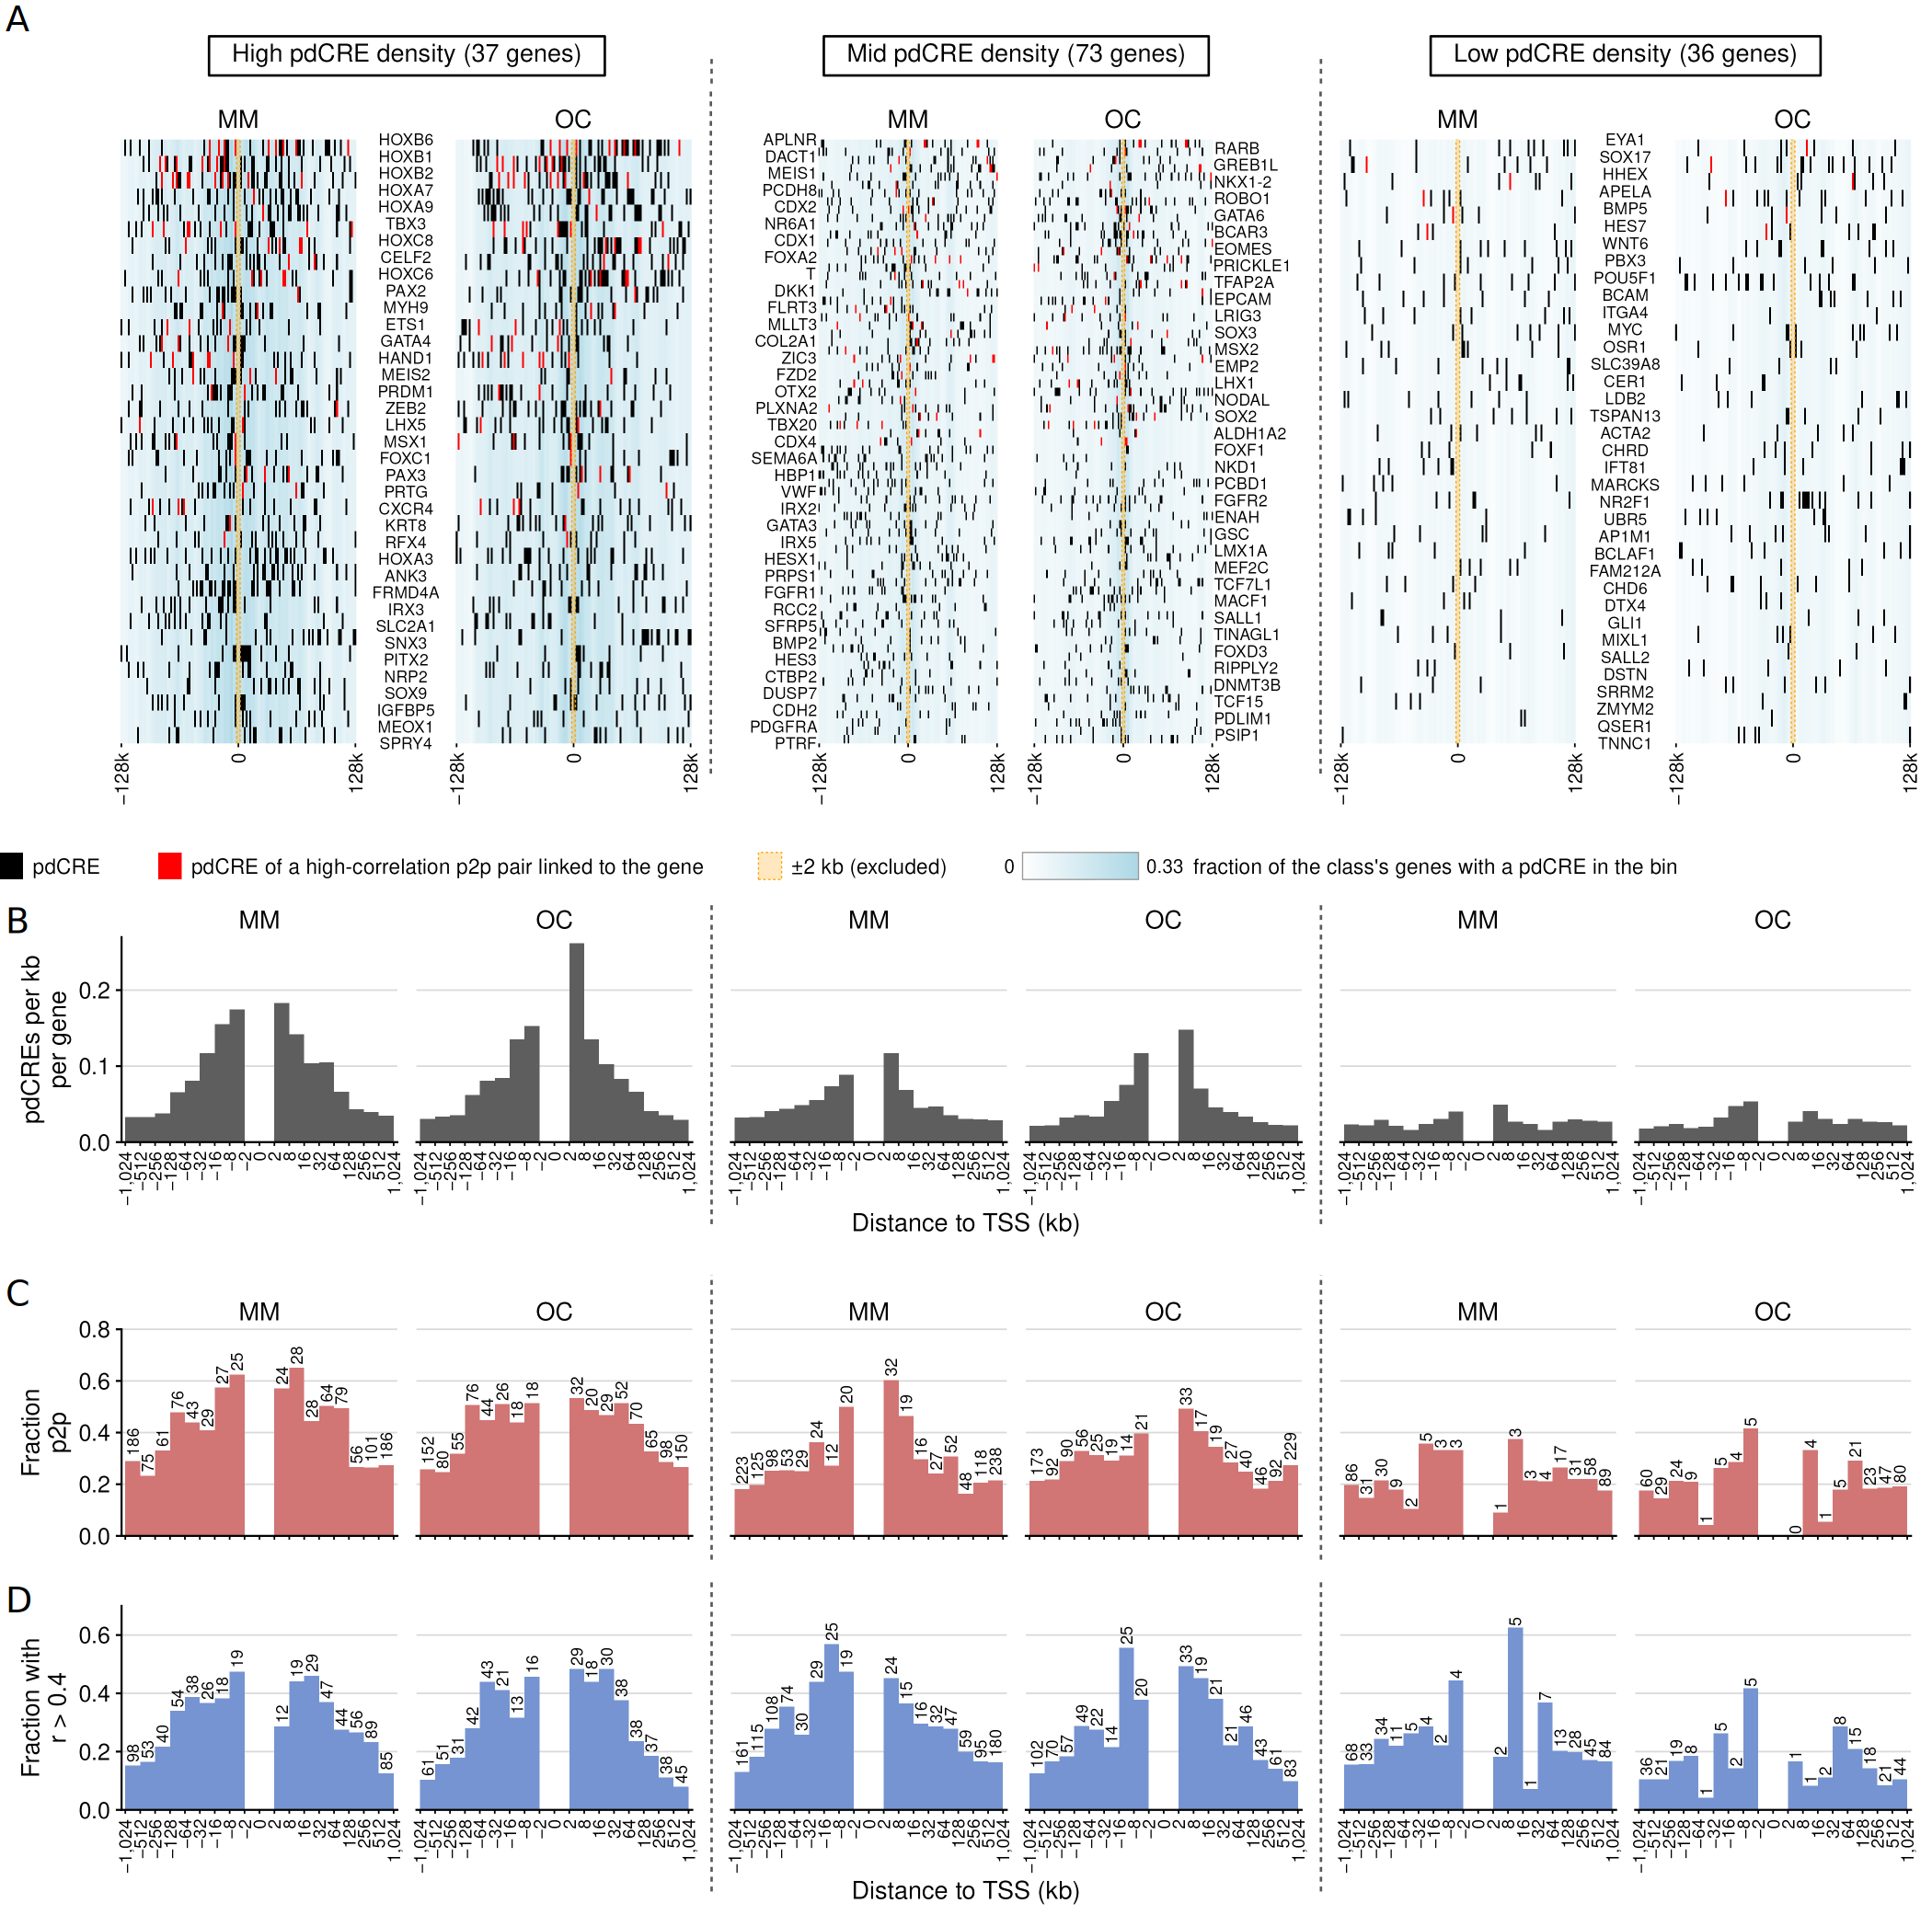

In [7]:
img6 <- local({
    # the header band of the density panel: the rows above the gap between the header boxes and the MM / OC strips, read
    # in the first class block (columns 10-33% of the width: no y-axis title, no dashed separator)
    m <- rA; cols <- seq(round(0.10 * dim(m)[2]), round(0.33 * dim(m)[2]))
    ink <- rowSums(m[, cols, 1] < 0.6 & m[, cols, 2] < 0.6 & m[, cols, 3] < 0.6) > 0
    r <- rle(ink); ends <- cumsum(r$lengths); starts <- ends - r$lengths + 1
    k <- which(r$values)
    box_end <- ends[k[1]]; next_ink <- starts[k[2]]
    cut <- (box_end + next_ink) %/% 2
    stopifnot(box_end > 40, box_end < 200, next_ink - box_end >= 20, cut < 260)
    hdr <- m[seq_len(cut), , , drop = FALSE]; dens <- m[-seq_len(cut), , , drop = FALSE]
    stopifnot(dim(hdr)[2] == dim(rB)[2])
    land <- array(0, c(dim(hdr)[1] + dim(rB)[1], dim(hdr)[2], dim(hdr)[3]))
    land[seq_len(dim(hdr)[1]), , ] <- hdr; land[dim(hdr)[1] + seq_len(dim(rB)[1]), , ] <- rB
    list(A = land, key = rKey, B = dens, C = rC, D = rD)
})
h6 <- sapply(img6, function(m) dim(m)[1] / 600); W6 <- dim(img6[[1]])[2] / 600        # inches
GAP6 <- 0.06; tot6 <- sum(h6) + GAP6 * (length(h6) - 1)
draw_abcd <- function() {
    grid::grid.newpage(); y <- tot6
    for (k in names(img6)) {
        vp <- grid::viewport(x = 0, y = (y - h6[[k]]) / tot6, width = 1, height = h6[[k]] / tot6, just = c("left", "bottom"))
        grid::pushViewport(vp); grid::grid.raster(img6[[k]], interpolate = TRUE); grid::popViewport()
        if (k != "key") grid::grid.text(k, x = grid::unit(0.02, "in"), y = grid::unit(y - 0.02, "in"), just = c("left", "top"),
                                        gp = grid::gpar(fontsize = 9, fontface = "bold", fontfamily = "Helvetica"))
        y <- y - h6[[k]] - GAP6 }
}
options(repr.plot.width = W6, repr.plot.height = tot6, repr.plot.res = 300)
draw_abcd()

## 5. Figs 6E and 6F

E: accessibility against expression over the 24 homologous states, for two example pairs and the two conserved pairs of
Pdgfra. F: the Pdgfra locus in ES-cell Hi-C: shaman score map, virtual 4C from the TSS, the linked pdCREs and the genes.

In [8]:
EX <- data.table(gene = c("CDX4", "EPCAM"), mm_locid = c("mm_loc_104944", "mm_loc_45318"), oc_locid = c("oc_loc_105482", "oc_loc_51640"))
acc_rows <- function(f, rows, states) { d <- fread(f); m <- as.matrix(d[, ..states]); cs <- colSums(m)
    m <- m[match(rows, d[[1]]), , drop = FALSE]; stopifnot(!anyNA(m)); log2(1e-5 + t(t(m) / cs)) }
rna_rows <- function(f, gns, states) { d <- fread(f); d[, gene := to_mouse_name(gene)]; d <- d[!duplicated(gene)]
    m <- as.matrix(d[match(gns, gene), ..states]); stopifnot(!anyNA(m)); m }
f_acc <- function(sp) file.path(O, "06_lineage_specificity", sprintf("%s_a_sum_by_sup_all_all.csv", sp))
f_rna <- function(sp) file.path(TABD, sprintf("%s_rna_by_sup_legc.csv", sp))
Amm <- acc_rows(f_acc("mm"), EX$mm_locid, rbomcs$mouse_mcc)
Aoc <- acc_rows(f_acc("oc"), EX$oc_locid, rbomcs$rabbit_mcc)
Rmm <- rna_rows(f_rna("mm"), EX$gene, rbomcs$mouse_mcc)
Roc <- rna_rows(f_rna("oc"), EX$gene, rbomcs$rabbit_mcc)
stopifnot(identical(homolog_states$mouse_mcc, rbomcs$mouse_mcc))
ed <- rbindlist(lapply(seq_len(nrow(EX)), function(i) rbind(
    data.table(gene = EX$gene[i], sp = "MM", acc = Amm[i, ], expr = Rmm[i, ], col = homolog_states$color),
    data.table(gene = EX$gene[i], sp = "OC", acc = Aoc[i, ], expr = Roc[i, ], col = homolog_states$color))))
fwrite(ed, file.path(TABD, "Fig6E_points.csv"))

In [9]:
HG <- "PDGFRA"; SG <- c("CDX4", "EPCAM", "PDGFRA@mm_loc_74967", "PDGFRA@mm_loc_75000")
W <- 7.3; H <- 2.9
EP <- 0.615; ETOP <- 0.435; EBOT <- 2.290
gname <- function(g) paste0(substr(g, 1, 1), tolower(substring(g, 2)))
ed <- fread(file.path(TABD, "Fig6E_points.csv")); ttl <- setNames(gname(unique(ed$gene)), unique(ed$gene))
pk <- grep("@", SG, value = TRUE)
hc <- fread(file.path(TABD, "S10_high_cor_p2p_pairs.csv"))
acc1 <- function(f, row, states) { d <- fread(f); m <- as.matrix(d[, ..states]); cs <- colSums(m); log2(1e-5 + m[match(row, d[[1]]), ] / cs) }
rna1 <- function(f, g, states) { d <- fread(f); d[, gene := to_mouse_name(gene)]; d <- d[!duplicated(gene)]; as.numeric(as.matrix(d[gene == g, ..states])) }
for (k in pk) { g <- sub("@.*", "", k); loc <- sub(".*@", "", k); h <- hc[gene == g & mm_locid == loc][1]; stopifnot(nrow(h) == 1, !is.na(h$oc_locid))
    ed <- rbind(ed, data.table(gene = k, sp = "MM", acc = acc1(f_acc("mm"), loc, rbomcs$mouse_mcc), expr = rna1(f_rna("mm"), g, rbomcs$mouse_mcc), col = homolog_states$color),
                    data.table(gene = k, sp = "OC", acc = acc1(f_acc("oc"), h$oc_locid, rbomcs$rabbit_mcc), expr = rna1(f_rna("oc"), g, rbomcs$rabbit_mcc), col = homolog_states$color))
    ttl[k] <- sprintf("%s, %+.0f kb", gname(g), h$mm_dist / 1e3) }
er <- ed[, .(r = cor(acc, expr)), by = .(gene, sp)]
ex_plot <- function(g) {
    d <- ed[gene == g]; rr <- er[gene == g]
    ggplot(d, aes(acc, expr)) + geom_celltype_point(aes(fill = col), size = 1.05, stroke = 0.15) + scale_fill_identity() +
        geom_text(data = rr, aes(x = -Inf, y = Inf, label = sprintf("r = %.2f", r)), hjust = -0.1, vjust = 1.35, size = 5 / .pt, family = SUP_FONT, inherit.aes = FALSE) +
        facet_wrap(~sp, nrow = 1, scales = "free") +
        scale_x_continuous(breaks = scales::breaks_extended(3), expand = expansion(mult = 0.08)) +
        scale_y_continuous(breaks = scales::breaks_extended(4, Q = c(1, 5, 2, 4, 3)), expand = expansion(mult = c(0.08, 0.22))) +
        labs(x = NULL, y = NULL, title = ttl[[g]]) +
        theme_sup_facets() + theme(plot.title = element_text(size = 6.5, face = "italic", margin = margin(0, 0, 1, 0)), axis.text = element_text(size = 4.6),
            strip.text = element_text(size = 5.5, margin = margin(1, 0, 1, 0)), panel.spacing = unit(3, "pt"), plot.margin = margin(1, 4, 1, 1),
            panel.widths = unit(rep(EP, 2), "in"), panel.heights = unit(EP, "in"))
}
draw_E <- function() {
    grid::grid.newpage(); gt <- lapply(SG, \(g) ggplotGrob(ex_plot(g)))
    stack <- function(a, b) gtable::gtable_add_rows(rbind(a, b, size = "max"), unit(1, "null"), pos = nrow(a))
    gE <- cbind(stack(gt[[1]], gt[[3]]), stack(gt[[2]], gt[[4]]), size = "max"); pan <- gE$layout[grepl("^panel", gE$layout$name), ]
    tx <- function(lab, ...) grid::textGrob(lab, gp = grid::gpar(fontsize = 6, fontfamily = SUP_FONT), ...)
    gE <- gtable::gtable_add_cols(gE, unit(0.1, "in"), pos = 0)
    gE <- gtable::gtable_add_grob(gE, tx("Expression (log2 UMI fraction)", rot = 90), t = min(pan$t), b = max(pan$b), l = 1, clip = "off")
    xt <- tx("Accessibility (log2 UMI fraction)", y = unit(1, "npc") - unit(1, "pt"), vjust = 1)
    gE <- gtable::gtable_add_rows(gE, grid::grobHeight(xt) + unit(1, "pt"), pos = -1)
    gE <- gtable::gtable_add_grob(gE, xt, t = nrow(gE), l = min(pan$l) + 1, r = max(pan$r) + 1, clip = "off")
    hin <- function(i) grid::convertHeight(sum(gE$heights[i]), "in", valueOnly = TRUE)
    a <- hin(seq_len(min(pan$t) - 1)); b <- hin((max(pan$b) + 1):nrow(gE))
    grid::pushViewport(grid::viewport(x = 0, y = grid::unit(H - ETOP + a, "in"), width = grid::unit(WS, "in"), height = grid::unit(EBOT - ETOP + a + b, "in"),
                                      just = c("left", "top"))); grid::grid.draw(gE); grid::popViewport() }

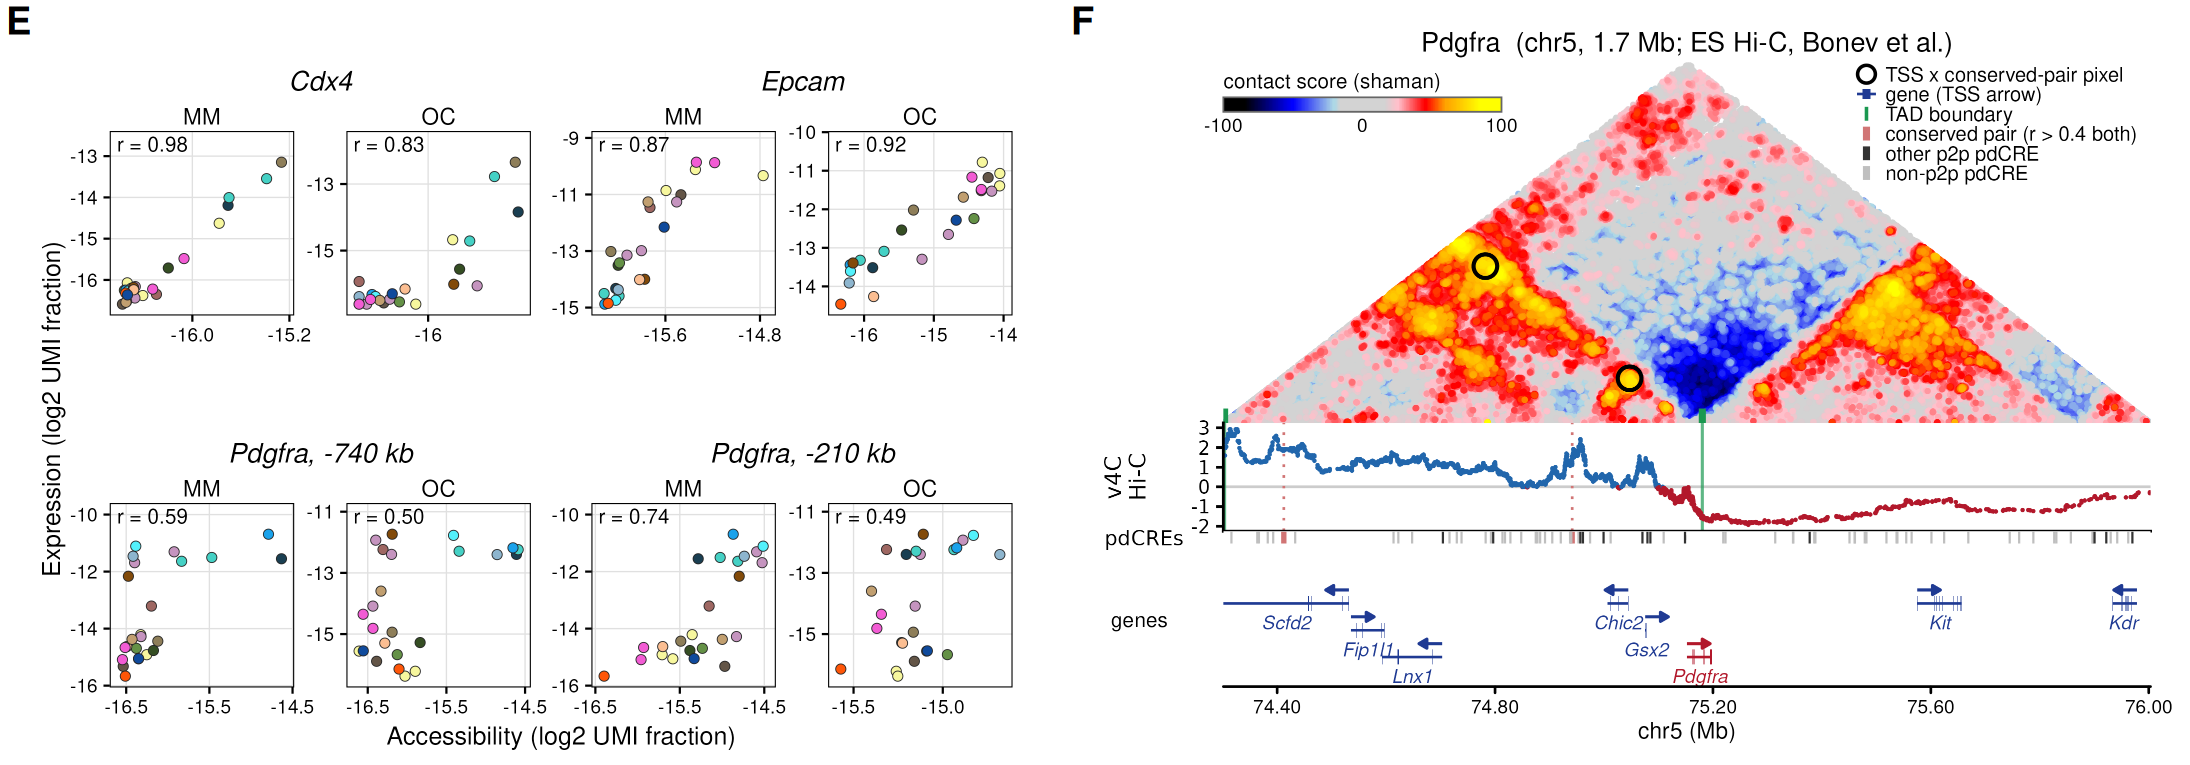

In [10]:
# F: the viewpoint and the red pdCREs of the gene, then the Hi-C map, the virtual 4C and the tracks
e <- new.env(); assign("g", HG, e); assign("MINOFF", 2000, e)
local(envir = e, {
    el_v4c = function(obs, shuf, centre) {
        p = sort(obs - centre); s = sort(shuf - centre); p = p[abs(p) >= MINOFF]; s = s[abs(s) >= MINOFF]; n = length(p)
        if (n < 20) return(NULL)
        k = if (n >= 200) 50L else 20L; r = n / max(length(s), 1)
        a = pmax(seq_len(n) - k %/% 2, 1L); b = pmin(a + k - 1L, n); a = pmax(b - k + 1L, 1L)
        ns = findInterval(p[b], s) - findInterval(p[a] - 1e-9, s)
        data.frame(x = p, v = log2(k / (r * ns + 0.5)), k = k)
    }
    ns = data.table::fread(data_path("mm_namespace_2025.csv"))
    hcr = data.table::fread(file.path(TABD, "S10_high_cor_p2p_pairs.csv"))[group != "" & !is.na(group) & group != "c"]
    tss_mm = data.table::fread(data_path("rbog_tss.csv"))[species == "mm"]
    lk = data.table::fread(file.path(TABD, "s10_links.csv"))[species == "mm" & abs(dist) > 2000 & abs(dist) <= 2^20]
    lk = merge(lk, ns[, .(locid = mm_locid, chrom, mid = (start + end) %/% 2L)], by = "locid")
    hc = merge(hcr, ns[, .(mm_locid, chrom, mid = (start + end) %/% 2L)], by = "mm_locid")
    hc[, tss_pos := mapply(function(g, ch, m) { t = tss_mm[gene == g & chrom == ch]; t$start[which.min(abs(t$start - m))] }, gene, chrom, mid)]
    gv = hc[, .N, by = .(gene, chrom, tss_pos)][order(gene, -N)][!duplicated(gene)]
    G = gv[gene == g]; stopifnot(nrow(G) == 1); cen = G$tss_pos; R = unique(hc[gene == g, .(mm_locid, mid)])
    lk = lk[gene == g][, set := fifelse(paste(locid, gene) %in% paste(hc$mm_locid, hc$gene), "red", fifelse(mode == "p2p", "p2p other", "non-p2p"))]
    ns_mm = data.table::fread(file.path(O, "01_crecls", "mm_notss_noctcf.csv"))[, .(locid = mm_locid, chrom, mid = (start + end) %/% 2L)]
    COL = c(red = "#D17575", `p2p other` = "grey20", `non-p2p` = "grey75")
    win = data.table::fread(data_path("fig6f_window.csv")); stopifnot(win$gene == g, win$chrom == G$chrom)
    CLEN = win$chrom_length
    half = min(max(3e5, 1.15 * max(abs(R$mid - cen))), 1.1e6); s = max(round(cen - half), 0); e = min(round(cen + half), CLEN - 1)
    v4 = data.table::fread(data_path("fig6f_v4c.csv"))
    vb = el_v4c(v4[set == "observed", pos2], v4[set == "shuffle", pos2], cen)
    ins_all = data.table::fread(data_path("fig6f_insulation.csv"))
    ins_all[, pos := (start + end) %/% 2L]; setorder(ins_all, pos)
    thr = win$ins_q20
    ins_all[, ins_sm := frollmean(ins, 25, align = "center", na.rm = TRUE)][, lmin := frollapply(ins_sm, 201, min, align = "center")]
    bnd = ins_all[!is.na(lmin) & ins_sm == lmin & ins_sm < thr, pos]; bnd = bnd[c(TRUE, diff(bnd) > 1e5)]; B = bnd[bnd > s & bnd < e]
    xs = scale_x_continuous(limits = c(s, e), expand = c(0, 0), labels = function(x) sprintf("%.2f", x / 1e6))
    marks = list(geom_vline(xintercept = R$mid, colour = COL[["red"]], linetype = "dotted", linewidth = 0.3),
                 geom_vline(xintercept = cen, colour = "#B2182B", linetype = "dashed", linewidth = 0.4),
                 geom_vline(xintercept = B, colour = "#1A9850", linewidth = 0.35, alpha = 0.7))
    noxt = theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(), plot.margin = margin(0, 4, 0, 4))
    tri = function(pts, lab, ps) {
        pts = pts[pts$start2 > pts$start1 & pts$start1 >= s & pts$start2 <= e, c("start1", "start2", "score")]
        shaman_gplot_map_score(pts, interval_range = data.frame(start = s, end = e), point_size = ps, add_axis = FALSE) +
            annotate("point", x = (R$mid + cen) / 2, y = abs(R$mid - cen) / 2, shape = 21, size = 2.2, stroke = 0.7, colour = "black", fill = NA) +
            annotate("segment", x = B, xend = B, y = 0, yend = (e - s) * 0.02, colour = "#1A9850", linewidth = 0.8) +
            annotate("text", x = s + (e - s) * 0.01, y = (e - s) / 2 * 0.95, label = lab, hjust = 0, vjust = 1, size = 2.8, fontface = "bold") +
            theme(plot.margin = margin(2, 4, 0, 4), panel.grid = element_blank()) }
    v4p = function(Vj, lab) { z = if (is.null(Vj)) data.frame(x = numeric(0), v = numeric(0)) else Vj[Vj$x + cen >= s & Vj$x + cen <= e, ]
        ggplot(z, aes(x + cen, pmax(pmin(v, 3), -2), colour = v > 0)) + geom_hline(yintercept = 0, colour = "grey80") +
            marks + geom_point(size = 0.08) + scale_colour_manual(values = c(`TRUE` = "#2166AC", `FALSE` = "#B2182B"), guide = "none") + xs +
            scale_y_continuous(limits = c(-2, 3)) + labs(x = NULL, y = sprintf("v4C\n%s", lab)) + theme_classic(base_size = 7) + noxt }
    pb = as.data.frame(data.table::fread(data_path("fig6f_score.csv.gz")))
    t1 = tri(pb, "Bonev ES Hi-C", 0.05) + labs(title = sprintf("%s  %s:%s  |  view 1M (%.2f Mb)  |  %d red pdCREs  |  Bonev ES Hi-C vs mESC Micro-C",
        g, G$chrom, format(cen, big.mark = ","), (e - s) / 1e6, nrow(R))) + theme(plot.title = element_text(size = 8, face = "bold"))
    L = lk[mid >= s & mid <= e][order(set != "red")]; U = ns_mm[chrom == G$chrom & mid >= s & mid <= e & !locid %in% L$locid]
    pt = ggplot(L) + geom_segment(data = U, aes(x = mid, xend = mid, y = 0.3, yend = 0.7), colour = "grey88", linewidth = 0.2) +
        geom_segment(aes(x = mid, xend = mid, y = 0, yend = 1, colour = set), linewidth = ifelse(L$set == "red", 0.6, 0.25)) +
        geom_vline(xintercept = cen, colour = "#B2182B", linetype = "dashed", linewidth = 0.4) +
        scale_colour_manual(values = COL, guide = "none") + xs + scale_y_continuous(breaks = NULL) +
        labs(x = sprintf("%s (Mb)", G$chrom), y = "pdCREs", caption = paste0("triangles: shaman score (k = 100) vs each dataset's own shuffle; circles = TSS x red-pdCRE pixel\n",
            "v4C: kNN log2(obs/shuffled), contacts < 2 kb from the TSS excluded from both; green = TAD boundaries from Bonev insulation")) +
        theme_classic(base_size = 7) + theme(axis.line.y = element_blank(), plot.margin = margin(0, 4, 2, 4), plot.caption = element_text(size = 5.5))
})
t1 <- e$t1 + labs(title = sprintf("%s  (%s, %.1f Mb; ES Hi-C, Bonev et al.)", gname(HG), e$G$chrom, (e$e - e$s) / 1e6)) +
    theme(plot.title = element_text(size = 6.5, face = "plain", hjust = 0.5, family = SUP_FONT, margin = margin(0, 0, 1, 0)))
t1$layers <- Filter(function(l) !(inherits(l$geom, "GeomText") && "label" %in% names(l$aes_params)), t1$layers)
e$marks <- e$marks[-2]
pv <- e$v4p(e$vb, "Hi-C") + theme(axis.title.y = element_text(size = 5.5), axis.text.y = element_text(size = 4.6))
s1 <- e$s; e1 <- e$e; SP <- e1 - s1; CH <- e$G$chrom
exa <- fread(data_path("fig6f_exons.csv"))[chrom == CH][, gene := sub(";.*", "", geneSymbol)]
exa <- exa[gene != "" & !grepl("^(Y_RNA|RNU|MIR|Mir[0-9]|Snor|SNOR|U[0-9]|Gm[0-9]|LOC|[A-Z]{1,2}[0-9]{5,}|[0-9]+$)", gene) & !grepl("Rik$", gene)]
gn <- exa[, .(gs = min(start), ge = max(end), strand = strand[1]), by = gene][ge - gs < 3e6 & ge >= s1 & gs <= e1][order(gs)]
ex <- exa[gene %in% gn$gene & end >= s1 & start <= e1]
lv <- integer(nrow(gn)); ends <- numeric()
for (i in seq_len(nrow(gn))) { k <- which(ends < gn$gs[i] - 0.09 * SP)[1]; if (is.na(k)) { ends <- c(ends, gn$ge[i]); k <- length(ends) } else ends[k] <- gn$ge[i]; lv[i] <- k }
MAXLV <- 99L; keep <- lv <= MAXLV | toupper(gn$gene) == HG
gn <- gn[keep]; lv <- lv[keep]; ex <- ex[gene %in% gn$gene]
gn[, y := -lv]; ex[gn, on = "gene", y := i.y]; gn[, `:=`(tss = fifelse(strand > 0, gs, ge), dir = fifelse(strand > 0, 1, -1))]
gn[, hl := toupper(gene) == HG]; ex[gn, on = "gene", hl := i.hl]
GC <- c(`TRUE` = "#B2182B", `FALSE` = "#1F3A93")
pg <- ggplot() + geom_segment(data = gn, aes(x = pmax(gs, s1), xend = pmin(ge, e1), y = y, yend = y, colour = hl), linewidth = .3) +
    geom_rect(data = ex, aes(xmin = pmax(start, s1), xmax = pmin(end, e1), ymin = y - .28, ymax = y + .28, fill = hl)) +
    geom_segment(data = gn[tss >= s1 & tss <= e1], aes(x = tss, xend = tss + dir * .025 * SP, y = y + .5, yend = y + .5, colour = hl), linewidth = .35,
                 arrow = arrow(length = unit(2.2, "pt"), type = "closed")) +
    geom_text(data = gn, aes(x = pmin(pmax((pmax(gs, s1) + pmin(ge, e1)) / 2, s1 + .03 * SP), e1 - .03 * SP), y = y - .45, label = gene, colour = hl),
              size = 4.6 / .pt, vjust = 1, fontface = "italic", family = SUP_FONT) +
    scale_colour_manual(values = GC, guide = "none") + scale_fill_manual(values = GC, guide = "none") +
    scale_x_continuous(limits = c(s1, e1), expand = c(0, 0), labels = function(x) sprintf("%.2f", x / 1e6)) +
    scale_y_continuous(limits = c(-max(lv, 1) - 1.1, .9), expand = c(0, 0)) +
    labs(x = sprintf("%s (Mb)", CH), y = "genes") + theme_void(base_family = SUP_FONT) + coord_cartesian(clip = "off") +
    theme(axis.title.y = element_text(size = 5, angle = 0, vjust = 0.5, margin = margin(0, 4, 0, 0)), plot.margin = margin(0, 4, 0, 4),
          axis.line.x = element_line(linewidth = 0.3), axis.ticks.x = element_line(linewidth = 0.3), axis.ticks.length.x = unit(1.5, "pt"),
          axis.text.x = element_text(size = 4.6, margin = margin(1, 0, 0, 0)), axis.title.x = element_text(size = 5.5, margin = margin(1, 0, 0, 0)))
nG <- max(lv, 1)
pt <- e$pt + labs(caption = NULL, y = "pdCREs") +
    theme(axis.title.y = element_text(size = 5, angle = 0, vjust = 0.5), axis.text.x = element_blank(), axis.ticks.x = element_blank(),
          axis.title.x = element_blank(), axis.line.x = element_blank())
pt$layers <- Filter(function(l) !(inherits(l$geom, "GeomVline") && identical(l$aes_params$colour, "#B2182B")), pt$layers)
pal <- shaman_score_pal()
cbar <- ggplot() + annotation_raster(matrix(pal, nrow = 1), xmin = -100, xmax = 100, ymin = 0, ymax = 1) +
    annotate("rect", xmin = -100, xmax = 100, ymin = 0, ymax = 1, fill = NA, colour = "grey40", linewidth = 0.2) +
    scale_x_continuous(limits = c(-100, 100), breaks = c(-100, 0, 100), expand = c(0, 0)) + scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    labs(x = NULL, y = NULL, title = "contact score (shaman)") + theme_void(base_family = SUP_FONT) + coord_cartesian(clip = "off") +
    theme(axis.text.x = element_text(size = 4.6, margin = margin(1, 0, 0, 0)), plot.title = element_text(size = 5, margin = margin(0, 0, 1, 0)))
kl <- data.frame(y = 6:1, lab = c("TSS x conserved-pair pixel", "gene (TSS arrow)", "TAD boundary", "conserved pair (r > 0.4 both)", "other p2p pdCRE", "non-p2p pdCRE"))
key <- ggplot(kl, aes(0, y)) + theme_void(base_family = SUP_FONT) +
    annotate("point", x = 0, y = 6, shape = 21, size = 1.6, stroke = 0.6, colour = "black", fill = NA) +
    annotate("segment", x = -0.3, xend = 0.3, y = 5, yend = 5, colour = "#1F3A93", linewidth = 0.3) +
    annotate("rect", xmin = -0.12, xmax = 0.12, ymin = 4.75, ymax = 5.25, fill = "#1F3A93") +
    annotate("segment", x = 0, xend = 0, y = 4 - 0.35, yend = 4 + 0.35, colour = "#1A9850", linewidth = 0.4) +
    annotate("segment", x = 0, xend = 0, y = (3:1) - 0.35, yend = (3:1) + 0.35, colour = c("#D17575", "grey20", "grey75"), linewidth = 0.8) +
    geom_text(aes(x = 0.6, label = lab), hjust = 0, size = 4.8 / .pt, family = SUP_FONT) +
    scale_x_continuous(limits = c(-0.4, 9), expand = c(0, 0)) + scale_y_continuous(limits = c(0.4, 6.6), expand = c(0, 0))
t1 <- t1 + inset_element(cbar, left = 0.0, bottom = 0.80, right = 0.3, top = 0.97, align_to = "panel") +
    inset_element(key, left = 0.68, bottom = 0.66, right = 1.0, top = 1.0, align_to = "panel")
pH <- t1 / pv / pt / pg + plot_layout(heights = c(5, 1.5, 0.18, 0.62 * nG))
WS <- 3.55; WH <- W - WS
mS <- render_panel(draw_E, WS, H)
mH <- render_panel(pH, WH, H)
low_edge <- function(m, x0, x1) {
    g <- 0.299 * m[, , 1] + 0.587 * m[, , 2] + 0.114 * m[, , 3]; w <- ncol(g)
    cols <- max(1, round(x0 * w)):round(x1 * w); runs <- apply(g[, cols] < 0.45, 1, function(v) { r <- rle(v); max(c(0, r$lengths[r$values])) })
    max(which(runs > 0.15 * length(cols))) }
yS <- low_edge(mS, 0.15, 0.98); yH <- low_edge(mH, 0.25, 0.98)
HH <- H - (yH - yS) / 600
mH <- render_panel(pH, WH, HH)
yH <- low_edge(mH, 0.25, 0.98); offS <- 0; topH <- (yS - yH) / 600
crop_bottom <- function(m) { g <- rowSums(m[, , 1] < 0.98 | m[, , 2] < 0.98 | m[, , 3] < 0.98); max(which(g > 0)) / 600 + 0.05 }
HC <- max(crop_bottom(mS), topH + crop_bottom(mH))
draw_ef <- function() { grid::grid.newpage()
    grid::grid.raster(mS, x = 0, y = grid::unit(HC - offS, "in"), width = grid::unit(WS, "in"), height = grid::unit(H, "in"), just = c("left", "top"))
    grid::grid.raster(mH, x = grid::unit(WS, "in"), y = grid::unit(HC - topH, "in"), width = grid::unit(WH, "in"), height = grid::unit(HH, "in"), just = c("left", "top"))
    lg <- grid::gpar(fontsize = 9, fontface = "bold", fontfamily = SUP_FONT)
    grid::grid.text("E", x = grid::unit(0.02, "in"), y = grid::unit(HC - 0.02, "in"), just = c("left", "top"), gp = lg)
    grid::grid.text("F", x = grid::unit(WS + 0.02, "in"), y = grid::unit(HC - 0.02, "in"), just = c("left", "top"), gp = lg) }
options(repr.plot.width = W, repr.plot.height = HC, repr.plot.res = 300)
draw_ef()

## 6. Fig S11C

Contact of pdCREs with the TSS of the linked gene: mouse pdCRE-gene links 2 kb-1 Mb from the TSS, with the virtual 4C
value at the pdCRE (log2 observed / expected contacts) in ES-cell Hi-C and Micro-C. Red: the high-correlation p2p pdCREs
(the conserved pairs of section 3, r > 0.4 in both species; the other p2p pdCREs are left out); grey: the non-p2p
pdCREs. Kernel densities per distance stratum (upstream and downstream pooled), both curves of a panel scaled by its
larger maximum; dashed line, 2-fold enrichment, links above it shaded. Numbers: links (left) and the percentage of links
above 2-fold (right). The x axis is cut at ±3.

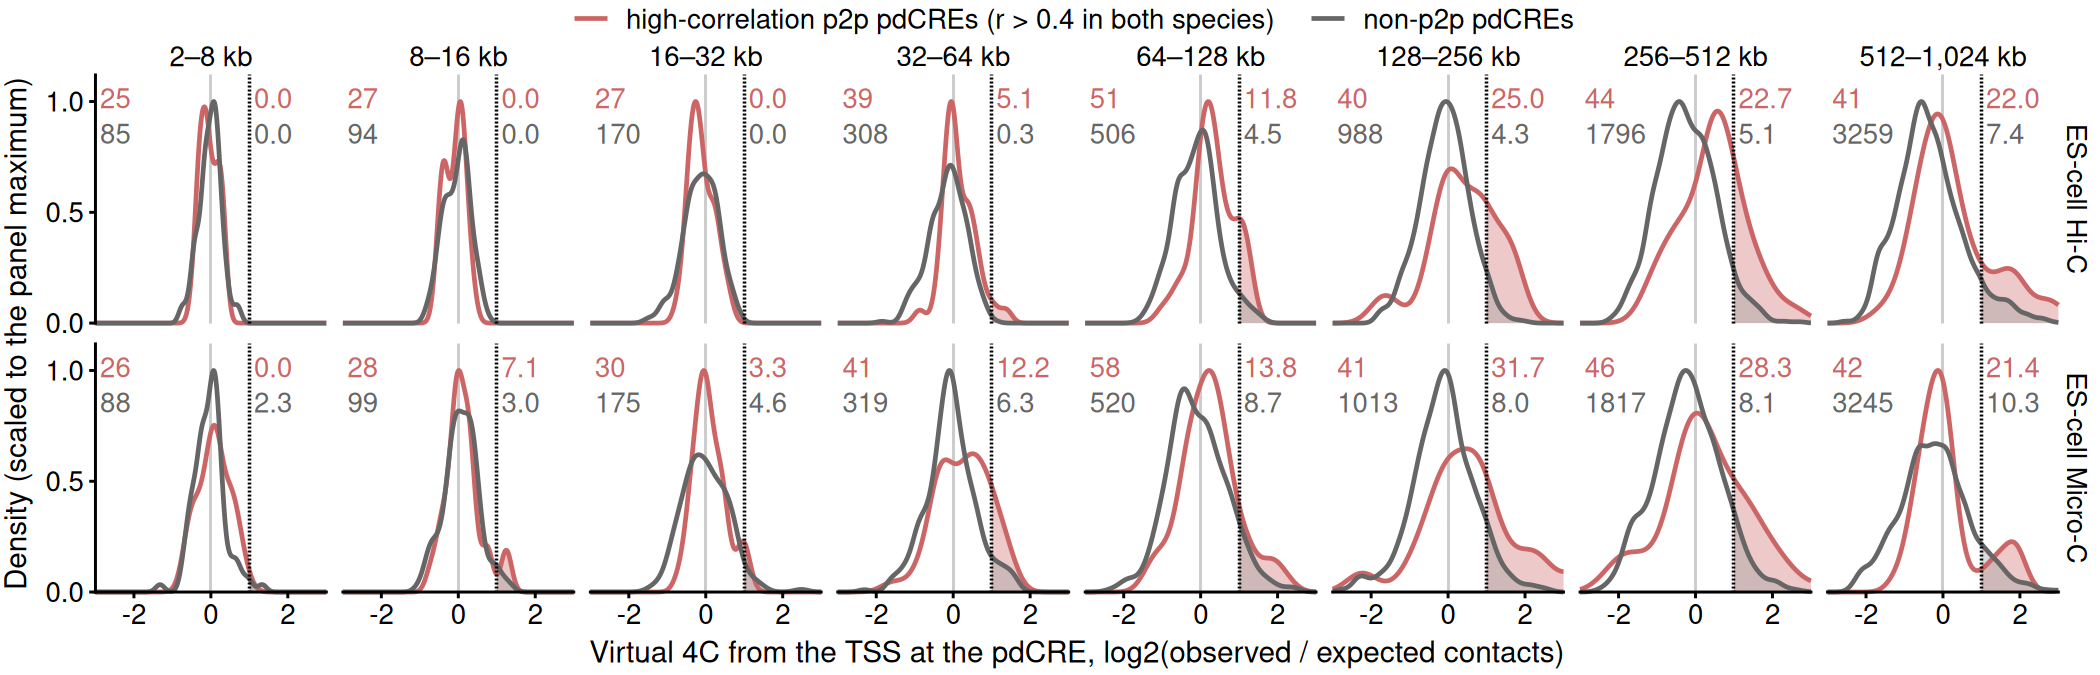

In [11]:
THR <- 1; XL <- c(-3, 3); PT <- 6.5                        # contact threshold (log2), shown x range, smallest text (pt)
COL <- c(p2p = "#CC6666", `non-p2p` = "grey40")
FILL <- c(p2p = "#CC6666", `non-p2p` = "grey60")
DS_LAB <- c(bonev = "ES-cell Hi-C", microc = "ES-cell Micro-C")
STRAT_LAB <- c("2–8 kb", "8–16 kb", "16–32 kb", "32–64 kb", "64–128 kb", "128–256 kb", "256–512 kb", "512–1,024 kb")   # 2^k bp edges
links <- fread(file.path(TABD, "s10_links.csv"))[species == "mm"]
v4 <- fread(data_path("link_v4c.csv.gz"))[set == "A_rbog_s10", .(dataset, locid, gene, v)]
L <- merge(links, v4, by = c("locid", "gene"))[abs(dist) > 2000 & abs(dist) <= 2^20]
hc <- fread(file.path(TABD, "S10_high_cor_p2p_pairs.csv"))
L[, dcor := FALSE][unique(hc[, .(locid = mm_locid, gene)]), dcor := TRUE, on = .(locid, gene)]
L <- L[dcor | mode != "p2p"]
L[, `:=`(stratum = cut(abs(dist), c(2000, 2^(13:20)), labels = STRAT_LAB),
         grp = factor(fifelse(mode == "p2p", "p2p", "non-p2p"), names(COL)), ds = factor(DS_LAB[dataset], DS_LAB))]
stopifnot(!anyNA(L$v), !anyNA(L$stratum))
# densities: all links of the group in the panel, evaluated on the shown range, scaled by the panel's larger maximum
dens <- L[, { d <- density(v, bw = "nrd0", n = 601, from = XL[1], to = XL[2]); .(x = d$x, y = d$y) }, by = .(ds, stratum, grp)]
dens[, y := y / max(y), by = .(ds, stratum)]
num <- L[, .(n = .N, pos = mean(v > THR)), by = .(ds, stratum, grp)][order(ds, stratum, grp)]
num[, ypos := fifelse(grp == "p2p", 1.06, 0.90)]
g <- ggplot(dens, aes(x, y)) +
    geom_vline(xintercept = 0, colour = "grey80", linewidth = 0.25) +
    geom_area(data = dens[x >= THR], aes(fill = grp, group = grp), alpha = 0.35, position = "identity", outline.type = "full",
              colour = NA) +
    geom_line(aes(colour = grp), linewidth = 0.4) +
    geom_vline(xintercept = THR, linetype = "22", linewidth = 0.3, colour = "black") +
    geom_text(data = num, aes(x = XL[1] + 0.12, y = ypos, label = n, colour = grp), hjust = 0, vjust = 1, size = PT / .pt,
              family = SUP_FONT, show.legend = FALSE) +
    geom_text(data = num, aes(x = THR + 0.12, y = ypos, label = sprintf("%.1f", 100 * pos), colour = grp), hjust = 0, vjust = 1,
              size = PT / .pt, family = SUP_FONT, show.legend = FALSE) +
    facet_grid(ds ~ stratum) +
    scale_colour_manual(values = COL, labels = c(p2p = "high-correlation p2p pdCREs (r > 0.4 in both species)", `non-p2p` = "non-p2p pdCREs"),
                        name = NULL) +
    scale_fill_manual(values = FILL, guide = "none") +
    scale_x_continuous(breaks = c(-2, 0, 2), expand = c(0, 0)) +
    scale_y_continuous(breaks = c(0, 0.5, 1), limits = c(0, 1.12), expand = c(0, 0)) +
    coord_cartesian(xlim = XL, clip = "off") +
    labs(x = "Virtual 4C from the TSS at the pdCRE, log2(observed / expected contacts)", y = "Density (scaled to the panel maximum)") +
    theme_sup(legend = "top") +
    theme(axis.text = element_text(size = PT), axis.title = element_text(size = 7), strip.text = element_text(size = PT),
          strip.text.y = element_text(angle = -90, size = PT), legend.text = element_text(size = PT),
          legend.key.width = unit(10, "pt"), legend.margin = margin(0, 0, 0, 0), legend.box.spacing = unit(1, "pt"),
          panel.spacing.x = unit(4, "pt"), panel.spacing.y = unit(5, "pt"), panel.grid = element_blank(),
          plot.margin = margin(1, 1, 1, 1))
options(repr.plot.width = 7.0, repr.plot.height = 2.25, repr.plot.res = 300)
g